In [77]:
import seaborn as sns
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from statsmodels.tsa.seasonal import seasonal_decompose

In [61]:
d_names= sns.get_dataset_names()
data = sns.load_dataset("flights")

In [62]:
print(data)

     year month  passengers
0    1949   Jan         112
1    1949   Feb         118
2    1949   Mar         132
3    1949   Apr         129
4    1949   May         121
..    ...   ...         ...
139  1960   Aug         606
140  1960   Sep         508
141  1960   Oct         461
142  1960   Nov         390
143  1960   Dec         432

[144 rows x 3 columns]


In [63]:
dat_n = pd.DataFrame(data)

In [64]:
data.describe()

,year,passengers
count,144.000000,144.000000
mean,1954.500000,280.298611
std,3.464102,119.966317
min,1949.000000,104.000000
25%,1951.750000,180.000000
50%,1954.500000,265.500000
75%,1957.250000,360.500000
max,1960.000000,622.000000


In [65]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   year        144 non-null    int64   
 1   month       144 non-null    category
 2   passengers  144 non-null    int64   
dtypes: category(1), int64(2)
memory usage: 2.9 KB


# Line plot

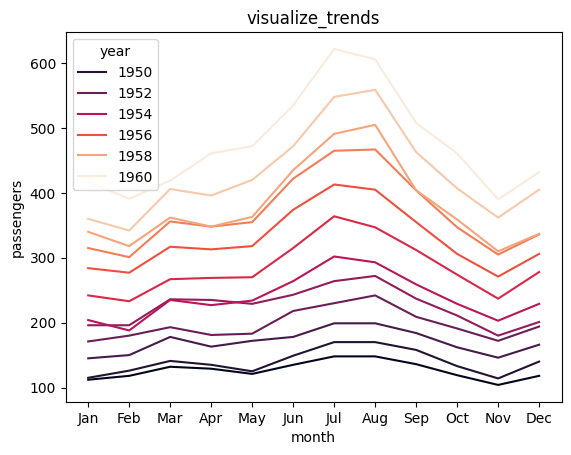

In [66]:
label = data.iloc[:,1]
plt.title("visualize_trends")
sns.lineplot(data=data,x='month',y='passengers',hue="year",palette='rocket')
plt.show()

In [67]:
pivot = pd.pivot_table(data=data,index='month',columns='year',values='passengers')

In [68]:
print(pivot)

year   1949  1950  1951  1952  1953  1954  1955  1956  1957  1958  1959  1960
month                                                                        
Jan     112   115   145   171   196   204   242   284   315   340   360   417
Feb     118   126   150   180   196   188   233   277   301   318   342   391
Mar     132   141   178   193   236   235   267   317   356   362   406   419
Apr     129   135   163   181   235   227   269   313   348   348   396   461
May     121   125   172   183   229   234   270   318   355   363   420   472
Jun     135   149   178   218   243   264   315   374   422   435   472   535
Jul     148   170   199   230   264   302   364   413   465   491   548   622
Aug     148   170   199   242   272   293   347   405   467   505   559   606
Sep     136   158   184   209   237   259   312   355   404   404   463   508
Oct     119   133   162   191   211   229   274   306   347   359   407   461
Nov     104   114   146   172   180   203   237   271   305   31

In [69]:
dat_n

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


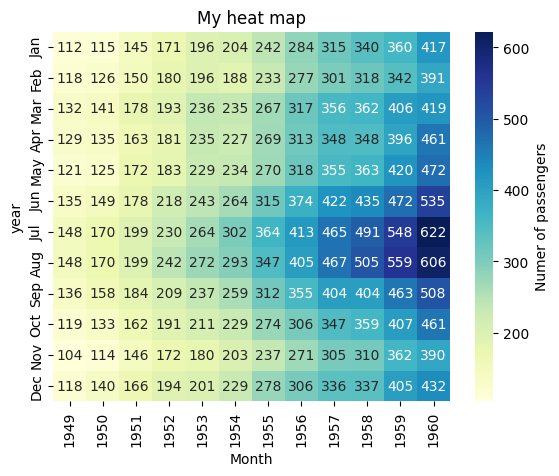

In [70]:
plt.title("My heat map")
sns.heatmap(data=pivot,annot=True,cmap='YlGnBu',cbar_kws={'label':"Numer of passengers"},fmt='g')
plt.xlabel("Month")
plt.ylabel("year")
plt.show()

# **TSACOMPONENTS**

In [71]:
flights_monthly = dat_n.groupby(['year','month'])['passengers'].sum().reset_index()


In [72]:
flights_monthly


,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


In [73]:
flights_monthly['date'] = pd.to_datetime(flights_monthly['year'].astype(str) + '-' + flights_monthly['month'].astype(str),format='%Y-%b')




In [75]:
flights_monthly.set_index('date',inplace=True)

In [76]:
flights_monthly

,year,month,passengers
date,,,
1949-01-01,1949,Jan,112
1949-02-01,1949,Feb,118
1949-03-01,1949,Mar,132
1949-04-01,1949,Apr,129
1949-05-01,1949,May,121
...,...,...,...
1960-08-01,1960,Aug,606
1960-09-01,1960,Sep,508
1960-10-01,1960,Oct,461


<Figure size 1500x1000 with 0 Axes>

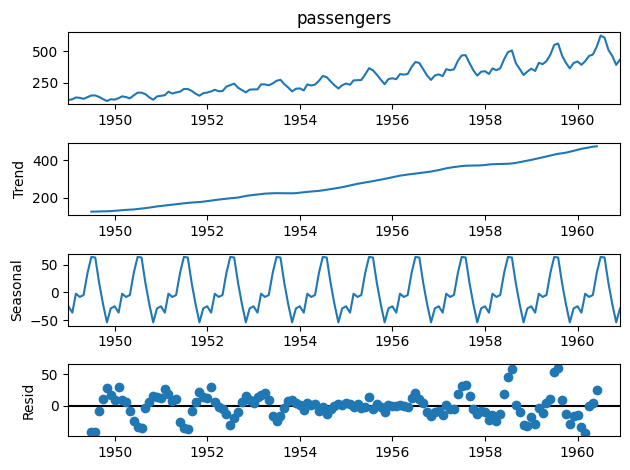

In [78]:
decomposition = seasonal_decompose(flights_monthly['passengers'],period=12,model='additive')

plt.figure(figsize=(15,10))
decomposition.plot()
plt.show()

c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<Figure size 1500x1000 with 0 Axes>

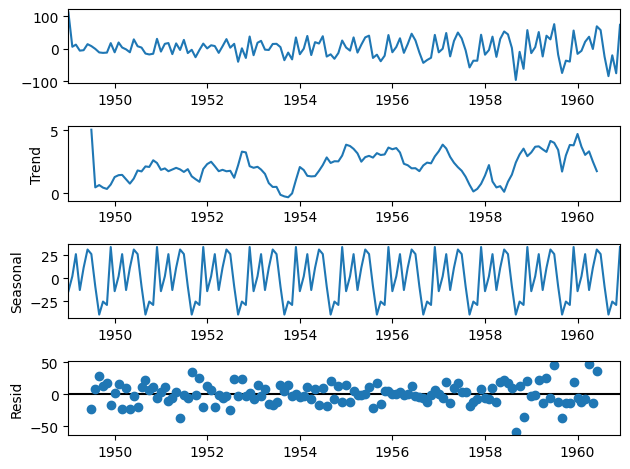

In [81]:
model = ARIMA(flights_monthly['passengers'],order=(1,1,1))

model_fit = model.fit()


residual = model_fit.resid

decomposition = seasonal_decompose(residual,period=12,model='additive')
plt.figure(figsize=(15,10))
decomposition.plot()
plt.show()